## Mission 1: Reconnaissance

I opened https://books.toscrape.com/catalogue/page-1.html, right-clicked a book card, chose Inspect, and expanded `<article class="product_pod">`.

| Data Needed | HTML Tag / Class Found | Your Notes |
|---|---|---|
| Book Title | `<h3><a href="catalogue/a-light-in-the-attic_1000/index.html" title="A Light in the Attic">A Light in the ...</a></h3>` | The full title is in the title attribute of the link. The visible text is cut off ("A Light in the ..."), so I read the attribute instead. |
| Price | `<div class="product_price"><p class="price_color">£51.77</p>` | Text starts with the £ sign, so I remove it and convert the number to a float (51.77). |
| Rating | `<p class="star-rating Three">` | The rating is stored as a word in the second CSS class (One, Two, Three, Four, Five). The five star icons are always present, so counting them does not work. I map the word to 1 to 5. |
| Availability | `<p class="instock availability"><i class="icon-ok"></i> In stock</p>` | The text "In stock" is surrounded by line breaks and spaces, so I use .strip(). |

**Extra observations**
- Each book is `<article class="product_pod">` inside an `<li>`, and the 20 cards sit in `<ol class="row">`.
- The page shows "1000 results" and "Page 1 of 50", so the catalogue has 50 pages with 20 books each.
- The book link is in `h3 > a[href]`, which I use to build the product URL (Bonus 2).

In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

url = "https://books.toscrape.com/catalogue/page-1.html"
response = requests.get(url)
response.encoding = "utf-8"
soup = BeautifulSoup(response.text, "html.parser")

books = soup.find_all("article", class_="product_pod")
print("Books found:", len(books))

data = []
for book in books:
    title = book.h3.a["title"]
    price_text = book.find("p", class_="price_color").text
    price = float("".join(ch for ch in price_text if ch.isdigit() or ch == "."))
    rating_word = book.find("p", class_="star-rating")["class"][1]
    rating = RATING_MAP[rating_word]
    availability = book.find("p", class_="availability").text.strip()
    data.append({"Title": title, "Price": price, "Rating": rating, "Availability": availability})

df = pd.DataFrame(data)
print(df.head())
print(df.dtypes)

Books found: 20
                                   Title  Price  Rating Availability
0                   A Light in the Attic  51.77       3     In stock
1                     Tipping the Velvet  53.74       1     In stock
2                             Soumission  50.10       1     In stock
3                          Sharp Objects  47.82       4     In stock
4  Sapiens: A Brief History of Humankind  54.23       5     In stock
Title               str
Price           float64
Rating            int64
Availability        str
dtype: object


## Mission 3: Scale the Operation

In [6]:
import time

BASE = "https://books.toscrape.com/catalogue/"

def scrape_page(page_number):
    """Scrape one catalogue page and return a list of book records."""
    url = f"{BASE}page-{page_number}.html"
    response = requests.get(url, timeout=30)
    if response.status_code != 200:
        return None                              # page does not exist
    response.encoding = "utf-8"
    soup = BeautifulSoup(response.text, "html.parser")

    records = []
    for book in soup.find_all("article", class_="product_pod"):
        price_text = book.find("p", class_="price_color").text
        price = float("".join(ch for ch in price_text if ch.isdigit() or ch == "."))
        rating_word = book.find("p", class_="star-rating")["class"][1]
        records.append({
            "Title": book.h3.a["title"],
            "Price": price,
            "Rating": RATING_MAP[rating_word],
            "Availability": book.find("p", class_="availability").text.strip(),
            "URL": BASE + book.h3.a["href"],
        })
    return records


def scrape_books(num_pages):
    """Loop over pages and return one DataFrame."""
    all_records = []
    for page in range(1, num_pages + 1):
        records = scrape_page(page)
        if records is None:
            break
        all_records.extend(records)
        print(f"Scraped page {page}: {len(records)} books")
        time.sleep(0.5)                          # polite delay
    return pd.DataFrame(all_records)


df = scrape_books(50)       # core mission: 3 pages = 60 books
print(df.head())
print("Shape:", df.shape)
print(df.dtypes)

Scraped page 1: 20 books
Scraped page 2: 20 books
Scraped page 3: 20 books
Scraped page 4: 20 books
Scraped page 5: 20 books
Scraped page 6: 20 books
Scraped page 7: 20 books
Scraped page 8: 20 books
Scraped page 9: 20 books
Scraped page 10: 20 books
Scraped page 11: 20 books
Scraped page 12: 20 books
Scraped page 13: 20 books
Scraped page 14: 20 books
Scraped page 15: 20 books
Scraped page 16: 20 books
Scraped page 17: 20 books
Scraped page 18: 20 books
Scraped page 19: 20 books
Scraped page 20: 20 books
Scraped page 21: 20 books
Scraped page 22: 20 books
Scraped page 23: 20 books
Scraped page 24: 20 books
Scraped page 25: 20 books
Scraped page 26: 20 books
Scraped page 27: 20 books
Scraped page 28: 20 books
Scraped page 29: 20 books
Scraped page 30: 20 books
Scraped page 31: 20 books
Scraped page 32: 20 books
Scraped page 33: 20 books
Scraped page 34: 20 books
Scraped page 35: 20 books
Scraped page 36: 20 books
Scraped page 37: 20 books
Scraped page 38: 20 books
Scraped page 39: 20 b

In [7]:
print("Shape:", df.shape)
print("Rows per page check:", len(df) / 20, "pages")
print("Last book:", df.iloc[-1]["Title"])
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df["Availability"].unique())

Shape: (1000, 5)
Rows per page check: 50.0 pages
Last book: 1,000 Places to See Before You Die
Title           0
Price           0
Rating          0
Availability    0
URL             0
dtype: int64
Duplicates: 0
<StringArray>
['In stock']
Length: 1, dtype: str


In [8]:
df.to_csv("competitor_books.csv", index=False)
print("Saved", len(df), "books to competitor_books.csv")

Saved 1000 books to competitor_books.csv


**Result:**
- Pages scraped: 50 (20 books each), the full catalogue
- DataFrame shape: (1000, 5)
- Columns: Title, Price, Rating, Availability, URL
- Data types: Price is float64, Rating is int64, the other columns are text

**Data check results:** no missing values, no duplicate rows, and every book has the availability "In stock". The dataset is saved as `competitor_books.csv`.

## Mission 4: Intelligence Analysis

In [9]:
# Q1. Most expensive
row = df.loc[df["Price"].idxmax()]
print("Q1 Most expensive:", row["Title"], "| £", row["Price"])

# Q2. Cheapest
row = df.loc[df["Price"].idxmin()]
print("Q2 Cheapest:", row["Title"], "| £", row["Price"])

# Q3. Average price
print("Q3 Average price: £", round(df["Price"].mean(), 2))

# Q4. Number of 5-star books
print("Q4 Five-star books:", (df["Rating"] == 5).sum())

# Q5. Percentage in stock
print("Q5 In stock:", round((df["Availability"] == "In stock").mean() * 100, 2), "%")

# Q6. Top 5 highest-rated (many tie at 5 stars, so ties are broken by lower price)
print("Q6 Top 5:")
top5 = df.sort_values(["Rating", "Price"], ascending=[False, True]).head(5)
print(top5[["Title", "Price", "Rating"]].to_string(index=False))

# Q7. Cheapest 5-star book
five_star = df[df["Rating"] == 5]
row = five_star.loc[five_star["Price"].idxmin()]
print("Q7 Cheapest 5-star:", row["Title"], "| £", row["Price"])

Q1 Most expensive: The Perfect Play (Play by Play #1) | £ 59.99
Q2 Cheapest: An Abundance of Katherines | £ 10.0
Q3 Average price: £ 35.07
Q4 Five-star books: 196
Q5 In stock: 100.0 %
Q6 Top 5:
                                                     Title  Price  Rating
                                An Abundance of Katherines  10.00       5
                                      Greek Mythic History  10.23       5
The Power Greens Cookbook: 140 Delicious Superfood Recipes  11.05       5
                                        Dear Mr. Knightley  11.21       5
                                       The Darkest Corners  11.33       5
Q7 Cheapest 5-star: An Abundance of Katherines | £ 10.0


In [10]:
print("Books at max price:", (df["Price"] == df["Price"].max()).sum())
print("Books at min price:", (df["Price"] == df["Price"].min()).sum())

Books at max price: 1
Books at min price: 1


## Mission 4: Intelligence Analysis

All answers below are based on the full scraped dataset of **1,000 books** from 50 pages.

1. **Most expensive book:** *The Perfect Play (Play by Play #1)* at **£59.99**.
2. **Cheapest book:** *An Abundance of Katherines* at **£10.00**.
3. **Average book price:** **£35.07**.
4. **5-star books:** **196** books have a 5-star rating (19.6% of the dataset).
5. **Books in stock:** **100%** of the scraped books are in stock.
6. **Top 5 highest-rated books:** many books tie at 5 stars, so I used the lower price as the tie-breaker:
   1. An Abundance of Katherines (£10.00, 5 stars)
   2. Greek Mythic History (£10.23, 5 stars)
   3. The Power Greens Cookbook: 140 Delicious Superfood Recipes (£11.05, 5 stars)
   4. Dear Mr. Knightley (£11.21, 5 stars)
   5. The Darkest Corners (£11.33, 5 stars)
7. **Cheapest 5-star book:** *An Abundance of Katherines* at **£10.00**.

In [11]:
print("Average price by rating:")
print(df.groupby("Rating")["Price"].mean().round(2))
print()
print("Books per rating:")
print(df["Rating"].value_counts().sort_index())
print()
avg = df["Price"].mean()
good_value = df[(df["Rating"] >= 4) & (df["Price"] < avg)]
print("4-5 star books priced below average:", len(good_value),
      f"({len(good_value) / len(df) * 100:.1f}% of all books)")

Average price by rating:
Rating
1    34.56
2    34.81
3    34.69
4    36.09
5    35.37
Name: Price, dtype: float64

Books per rating:
Rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

4-5 star books priced below average: 171 (17.1% of all books)


## Business Decision

**Manager's question:** which books would I prioritize when launching a competing online bookstore, and why?

**Evidence from the scraped data (1,000 books):**
1. **Price does not depend on rating.** The average price of 5-star books is £35.37, compared with £34.56 for 1-star books and an overall average of £35.07. Highly rated books are not more expensive, so the competitor charges no real premium for quality.
2. **There is a large pool of good-value books.** 171 books (17.1% of the catalogue) are rated 4 or 5 stars and priced below the average of £35.07. That is 45.6% of all 4-5 star books.
3. **Availability is not a differentiator.** 100% of the books are in stock, so a competitor cannot win on stock alone.

**Recommendation:** I would prioritize the 171 books rated 4 or 5 stars and priced below the £35.07 average, starting with the cheapest 5-star titles such as *An Abundance of Katherines* (£10.00). Because the data shows that high ratings do not come with higher prices, customers expect good quality at normal prices, so we should compete on a strong selection of top-rated, affordable books rather than on stock availability.

**Note:** the website states that its prices and ratings were randomly assigned, so this recommendation is based on the scraped dataset and is not a claim about real customer demand.

## Final Challenge: The CEO Has £100

In [12]:
import numpy as np

budget = 10000                                  # £100 in pence (avoids float errors)
prices = (df["Price"] * 100).round().astype(int).to_numpy()
ratings = df["Rating"].to_numpy()
n = len(df)

dp = np.zeros(budget + 1, dtype=np.int64)       # best total rating for each budget
take = np.zeros((n, budget + 1), dtype=bool)    # remembers which books were taken
for i in range(n):
    p, r = int(prices[i]), int(ratings[i])
    if p <= budget:
        candidate = dp[:budget + 1 - p] + r
        better = candidate > dp[p:]
        take[i, p:] = better
        dp[p:] = np.where(better, candidate, dp[p:])

w, chosen = budget, []
for i in range(n - 1, -1, -1):                  # trace back the chosen books
    if take[i, w]:
        chosen.append(i)
        w -= int(prices[i])

selected = df.iloc[chosen][["Title", "Price", "Rating"]]
print(selected.to_string(index=False))
print("Number of books:", len(selected))
print("Total cost: £", round(selected["Price"].sum(), 2))
print("Total rating score:", int(selected["Rating"].sum()))

                                                                                  Title  Price  Rating
                                                             An Abundance of Katherines  10.00       5
                             The Power Greens Cookbook: 140 Delicious Superfood Recipes  11.05       5
                                       Every Heart a Doorway (Every Heart A Doorway #1)  12.16       5
Naturally Lean: 125 Nourishing Gluten-Free, Plant-Based Recipes--All Under 300 Calories  11.38       5
                                                                  The Origin of Species  10.01       4
                                                                     Dear Mr. Knightley  11.21       5
                                                                   Greek Mythic History  10.23       5
                                                  Old School (Diary of a Wimpy Kid #10)  11.83       5
                          Superman Vol. 1: Before Truth (Superman by Gene

## Final Challenge: The CEO Has £100

**Goal:** choose books that maximize the total star rating without spending more than £100, buying each book at most once.

**Method:** a simple "cheapest first" or "highest rating first" approach is not guaranteed to be best, so I used a knapsack optimization (dynamic programming). Prices were converted to pence to avoid floating-point errors. The method checks every affordable combination and returns the one with the highest total rating.

**Selected books:**

| # | Title | Price (£) | Rating |
|---|---|---|---|
| 1 | An Abundance of Katherines | 10.00 | 5 |
| 2 | The Power Greens Cookbook: 140 Delicious Superfood Recipes | 11.05 | 5 |
| 3 | Every Heart a Doorway (Every Heart A Doorway #1) | 12.16 | 5 |
| 4 | Naturally Lean: 125 Nourishing Gluten-Free, Plant-Based Recipes--All Under 300 Calories | 11.38 | 5 |
| 5 | The Origin of Species | 10.01 | 4 |
| 6 | Dear Mr. Knightley | 11.21 | 5 |
| 7 | Greek Mythic History | 10.23 | 5 |
| 8 | Old School (Diary of a Wimpy Kid #10) | 11.83 | 5 |
| 9 | Superman Vol. 1: Before Truth (Superman by Gene Luen Yang #1) | 11.89 | 5 |

**Total cost:** £99.76 (within the £100 budget)
**Total rating score:** 44 (9 books)

**Justification:** the selection was computed from my scraped dataset of 1,000 books. The books cost about £10 to £12 each, so the budget buys 9 books, and nearly all of them are 5-star. No other combination of scraped books under £100 gives a higher total rating.

## Bonus Missions

- **Bonus 1 (scrape 5 pages instead of 3):** done. I scraped all 50 pages, which covers this bonus.
- **Bonus 2 (add the product page URL):** done. The `URL` column holds each book's product link, built from `h3 > a[href]`.
- **Bonus 3 (count books per star rating):** shown below with `value_counts()`.
- **Bonus 4 (bar chart of rating counts):** created with pandas and matplotlib, and saved as `rating_counts.png`.
- **Boss Level (all catalogue pages):** done. `scrape_books(50)` scraped the whole catalogue (1,000 books) with the same reusable logic.

Rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64


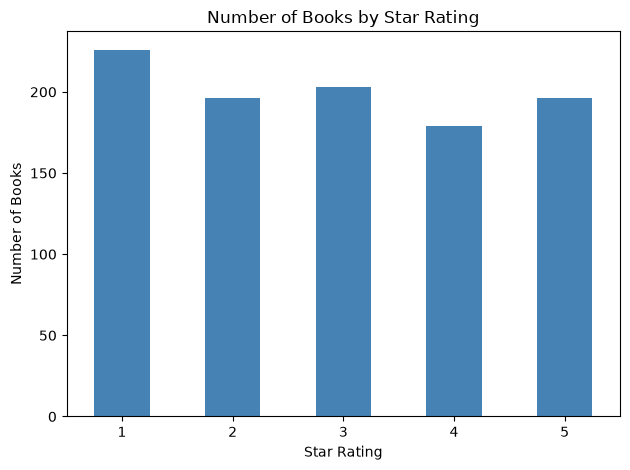

In [13]:
import matplotlib.pyplot as plt

rating_counts = df["Rating"].value_counts().sort_index()
print(rating_counts)

rating_counts.plot(kind="bar", color="steelblue")
plt.title("Number of Books by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("rating_counts.png")
plt.show()

**Bonus 3: Books per star rating**

| Star rating | Number of books |
|---|---|
| 1 star | 226 |
| 2 stars | 196 |
| 3 stars | 203 |
| 4 stars | 179 |
| 5 stars | 196 |

**Bonus 4: What the chart shows:** the books are spread fairly evenly across all five ratings. 1-star is the largest group (226 books) and 4-star is the smallest (179 books). This suggests the ratings are not concentrated in the high end, so a bookstore cannot assume that most books are well rated.

## Mission 6: Mission Debrief

**Scope:** I scraped all 50 catalogue pages of books.toscrape.com (1,000 books) using `requests`, `BeautifulSoup` and `pandas`. The data was saved as `competitor_books.csv`.

**Best business recommendation:** I would prioritize the 171 books rated 4 or 5 stars and priced below the £35.07 average, starting with the cheapest 5-star titles. The data shows that 5-star books cost about the same as 1-star books (£35.37 vs £34.56), so quality does not come with a premium price.

**Challenge faced:** the rating is not stored as a number but as a CSS class name (for example `star-rating Three`), and the visible titles are cut off with "...". I solved these by reading the second class and converting it with a `RATING_MAP` dictionary, and by reading the full title from the `title` attribute of the link.

**Result of the £100 challenge:** 9 books, total cost £99.76, total rating score 44.